# Leer un arreglo de trampas: qué números dicen que es bueno

**Pregunta:** ¿Qué números dicen si un arreglo de trampas es bueno, cómo discrepan la eficiencia, la uniformidad, la dispersión relativa y el balance de potencia sobre un mismo holograma, y qué oculta cada uno?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebook 01 de este tema (adónde va la luz)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Un holograma se juzga por las trampas que hace. Para un arreglo de cien trampas el juicio tiene que ser un puñado de números, y cada número responde una pregunta distinta: cuánta luz llegó a las trampas, cuán parecidas son las trampas, cuán lejos está la peor del resto y adónde fue el resto de la luz. Calcularás todos ellos en un arreglo de diez por diez para tres hologramas de calidad creciente, construirás un caso en que dos de ellos ordenan dos hologramas en sentido opuesto, verás cómo los pesos del objetivo cambian lo que significa uniforme y medirás cómo el balance de potencia depende de un radio que elige quien analiza.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m04_gs, m06_gsw

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C12, un arreglo cuadrado de 10 por 10 trampas (100 trampas, separadas 7,97 um) sobre el SLM de 256 por 256 píxeles del notebook anterior, con un presupuesto de 30 iteraciones y la semilla 20261028.

In [2]:
# caso C12: un arreglo cuadrado de 10 x 10 trampas, el arreglo de la comparación publicada
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
pitch_um = np.diff(np.unique(traps.x_m))[0] * 1e6
print(f"{len(traps)} trampas, separación {pitch_um:.2f} um, SLM {setup.n_pix} x {setup.n_pix}")
print(f"iteraciones del presupuesto: {rec['budget']['iterations']}, seed {rec['seed']}")

100 trampas, separación 7.97 um, SLM 256 x 256
iteraciones del presupuesto: 30, seed 20261028


## Método

Sea $I_m = |V_m|^2$ la fracción de la potencia de entrada en el pico de la trampa $m$ (notebook 01). Tres números resumen el arreglo. La eficiencia es $e = \sum_m I_m$. La uniformidad es $u = 1 - (\max I - \min I)/(\max I + \min I)$, que vale 1 para trampas iguales (Di Leonardo et al. 2007, ecuación 4, https://doi.org/10.1364/OE.15.001913; Polin et al. 2005, https://doi.org/10.1364/OPEX.13.005831, imprimen la misma razón sin el $1 -$ inicial, que es una no uniformidad, y las dos no deben mezclarse). La dispersión relativa es $\sigma = 100\,\mathrm{std}(I)/\mathrm{mean}(I)$ en porcentaje. Las trampas importan por su profundidad, que es proporcional a la intensidad, de modo que una dispersión de las intensidades es una dispersión de las profundidades: Manetsch et al. 2025 (https://arxiv.org/abs/2403.12021) informan una dispersión de profundidad de 11,4 por ciento tras Gerchberg-Saxton ponderado en un arreglo de unas 12.000 pinzas. Una cuarta cantidad, el balance de potencia, integra la potencia focal en vez de leer picos. Los pasos siguientes calculan todas para tres métodos, las rompen a propósito y las leen de nuevo.

Primero los hologramas. La superposición de prismas y lentes (M01) no itera, Gerchberg-Saxton simple (M04) itera con la amplitud fija al objetivo y Gerchberg-Saxton ponderado (M06) además reajusta las trampas; los notebooks siguientes los derivan, y aquí son tres arreglos de calidad distinta. La celda ejecuta cada uno durante las 30 iteraciones del caso e imprime sus tres números, leídos de los campos de las trampas `res.fields` que devuelve todo método.

In [3]:
# tres hologramas del mismo arreglo: la superposición, Gerchberg-Saxton simple y Gerchberg-Saxton ponderado
budget = Budget(rec["budget"]["iterations"])
runs = {}
runs["M01"] = m01_superposition.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
runs["M04"] = m04_gs.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
runs["M06"] = m06_gsw.run(setup, target, budget=budget, rng=Rng(rec["seed"]))
for name, res in runs.items():
    i = metrics.trap_intensities(res.fields)
    e, u, sigma = metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M01: e = 0.3280, u = 0.0003, sigma = 268.79 %
M04: e = 0.8174, u = 0.5064, sigma = 19.97 %
M06: e = 0.8049, u = 0.9705, sigma = 1.02 %


¿Concuerdan siempre los números? Responden preguntas distintas, y la uniformidad depende solo de la trampa más brillante y de la más tenue. Para ver la consecuencia, toma el holograma de M06, casi perfecto, y atenúa una trampa al 20 por ciento de su potencia, como si la hubieran bloqueado o desplazado. Luego pon ese arreglo junto al de Gerchberg-Saxton simple. La celda imprime $u$, $\sigma$ y $e$ de ambos.

In [4]:
# las mismas métricas sobre el holograma de M06 con una trampa atenuada al 20 por ciento, junto a GS simple (M04)
base = metrics.trap_intensities(runs["M04"].fields)
gsw = metrics.trap_intensities(runs["M06"].fields)
spoiled = gsw.copy()
spoiled[37] *= 0.2
for label, vec in (('M04, GS simple', base), ('M06 con una trampa al 20 por ciento', spoiled)):
    u, sigma, e = metrics.uniformity(vec), metrics.rel_std(vec), metrics.efficiency(vec)
    print(f"{label}: u = {u:.4f}, sigma = {sigma:.2f} %, e = {e:.4f}")
print(f"trampa más débil sobre el promedio del arreglo atenuado: {spoiled.min() / spoiled.mean():.2f}")

M04, GS simple: u = 0.5064, sigma = 19.97 %, e = 0.8174
M06 con una trampa al 20 por ciento: u = 0.3172, sigma = 8.14 %, e = 0.7986
trampa más débil sobre el promedio del arreglo atenuado: 0.20


La figura siguiente ordena la potencia de cada trampa, relativa al promedio, para los tres hologramas y para el arreglo atenuado, en un eje logarítmico.

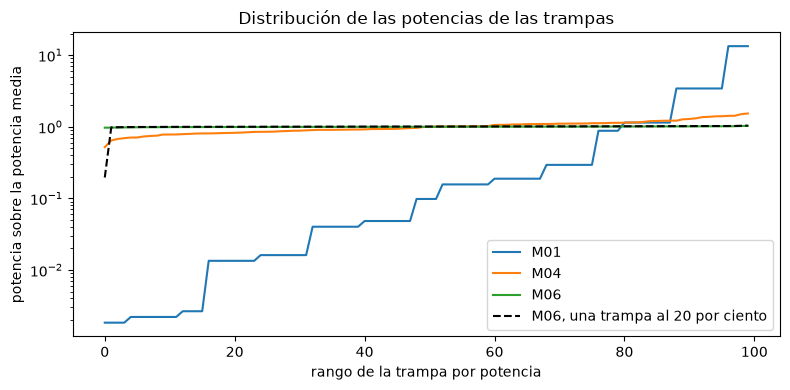

In [5]:
# la potencia de cada trampa relativa al promedio, ordenada, para los tres hologramas y el atenuado
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in runs.items():
    i = metrics.trap_intensities(res.fields)
    ax.semilogy(np.sort(i / i.mean()), label=name)
ax.semilogy(np.sort(spoiled / spoiled.mean()), "k--", label="M06, una trampa al 20 por ciento")
ax.set_xlabel("rango de la trampa por potencia")
ax.set_ylabel("potencia sobre la potencia media")
ax.set_title("Distribución de las potencias de las trampas")
ax.legend()
fig.tight_layout()
plt.show()

La superposición tiene trampas separadas por más de tres órdenes de magnitud, y los escalones son la simetría de la red: las trampas que la geometría trata igual reciben exactamente la misma potencia. Gerchberg-Saxton es una rampa suave de cerca de 0,5 a cerca de 1,6 veces el promedio, de modo que cada trampa está a un factor de unas tres de cualquier otra. Gerchberg-Saxton ponderado es plano a simple vista, y la curva punteada se distingue de él solo en un punto. El orden por $u$ pone a Gerchberg-Saxton simple (0,5064) por delante del arreglo atenuado (0,3172), porque la trampa tenue fija el mínimo. El orden por $\sigma$ pone al arreglo atenuado (8,14 por ciento) por delante de Gerchberg-Saxton simple (19,97 por ciento), porque 99 trampas son casi perfectas. Ningún orden es erróneo; responden peor trampa contra trampa típica. La figura no dice qué arreglo preferiría un experimento: eso depende de si perder una trampa arruina la corrida, como en el reordenamiento de átomos, o de si lo que importa es la profundidad media.

Un objetivo también puede pedir trampas desiguales, con pesos $w_m$ que son intensidades objetivo; entonces uniforme significa $I_m/w_m$ iguales, y las métricas se calculan sobre las intensidades divididas `trap_intensities(v, weights)`. La celda le pide a M06 un arreglo cuyas cinco columnas de la izquierda tienen peso 2 y cuyas cinco de la derecha tienen peso 1, e imprime las métricas sobre las potencias crudas y sobre las potencias divididas por los pesos.

In [6]:
# un objetivo cuyas cinco columnas de la izquierda piden el doble de potencia que las cinco de la derecha
heavy = np.array([t.id % 10 < 5 for t in traps])
weighted = Target.from_traps(TrapSet(replace(t, weight=2.0) if h else t for t, h in zip(traps, heavy)))
res_w = m06_gsw.run(setup, weighted, budget=budget, rng=Rng(rec["seed"]))
raw = metrics.trap_intensities(res_w.fields)
scaled = metrics.trap_intensities(res_w.fields, weighted.traps.weight)
for label, vec in (("intensidades crudas", raw), ("intensidades divididas por los pesos del objetivo", scaled)):
    print(f"{label}: u = {metrics.uniformity(vec):.4f}, sigma = {metrics.rel_std(vec):.2f} %")
print(f"potencia media de las trampas pesadas sobre las livianas: {raw[heavy].mean() / raw[~heavy].mean():.3f}")

intensidades crudas: u = 0.6545, sigma = 33.19 %
intensidades divididas por los pesos del objetivo: u = 0.9813, sigma = 0.80 %
potencia media de las trampas pesadas sobre las livianas: 1.993


Hasta aquí todo número salió de picos. El balance de potencia integra en cambio la potencia focal $|E|^2/N_{pix}$ de toda la grilla y la reparte entre la potencia dentro de un radio de cada trampa (2 bins, una celda de resolución, por defecto), la potencia dentro del mismo radio del eje óptico que no es una trampa, y el resto, que son fantasmas, colas y las réplicas plegadas. La celda calcula el campo focal de cada holograma e imprime las cuatro fracciones, que suman 1.

In [7]:
# adónde va la potencia de entrada, desde el campo focal de cada holograma (integrada en discos de 2 bins)
focal = {name: forward.fft_focal_field(res.phi, setup) for name, res in runs.items()}
shares = {name: metrics.power_budget(e, setup, traps) for name, e in focal.items()}
BUDGET_LABELS = {"traps": "trampas", "zero_order": "orden cero", "ghosts": "fantasmas", "remainder": "fuera de grilla"}
for name, share in shares.items():
    parts = ", ".join(f"{BUDGET_LABELS[k]} {v:.4f}" for k, v in share.items())
    print(f"{name}: {parts}")
    print(f"{name}: orden cero {share['zero_order']:.1e}, fuera de grilla {share['remainder']:.1e}")

M01: trampas 0.3517, orden cero 0.0000, fantasmas 0.6483, fuera de grilla 0.0000
M01: orden cero 3.2e-11, fuera de grilla 2.2e-16
M04: trampas 0.8765, orden cero 0.0000, fantasmas 0.1235, fuera de grilla 0.0000
M04: orden cero 3.3e-08, fuera de grilla 2.2e-16
M06: trampas 0.8631, orden cero 0.0000, fantasmas 0.1369, fuera de grilla 0.0000
M06: orden cero 9.9e-09, fuera de grilla 2.2e-16


El reparto depende del radio, que es una elección de quien analiza y no una propiedad del holograma. La celda recalcula el balance de M06 para radios de 1 a 8 bins.

In [8]:
# el mismo reparto para M06 cuando el disco alrededor de cada trampa crece de 1 a 8 bins
radii = [1, 2, 3, 4, 6, 8]
sweep = {r: metrics.power_budget(focal["M06"], setup, traps, r) for r in radii}
for r, share in sweep.items():
    print(f"radio {r}: en los discos de las trampas {share['traps']:.4f}, en los fantasmas {share['ghosts']:.4f}")

radio 1: en los discos de las trampas 0.6184, en los fantasmas 0.3816
radio 2: en los discos de las trampas 0.8631, en los fantasmas 0.1369
radio 3: en los discos de las trampas 0.9003, en los fantasmas 0.0997
radio 4: en los discos de las trampas 0.9083, en los fantasmas 0.0917
radio 6: en los discos de las trampas 0.9174, en los fantasmas 0.0826
radio 8: en los discos de las trampas 0.9237, en los fantasmas 0.0763


Dos fracciones se nombran aparte porque quienes diseñan las vigilan. El orden cero es el pico en el eje óptico, que un dispositivo ideal no crea para este arreglo; la fracción de fantasmas es la parte de la potencia fuera de los discos de las trampas y del eje. La celda imprime ambas para cada holograma.

In [9]:
# la fracción del pico en el orden cero y la fracción en fantasmas, un número por holograma
for name, e in focal.items():
    zero = metrics.zero_order_fraction(e, setup)
    ghost = metrics.ghost_fraction(e, setup, traps, 2)
    print(f"{name}: pico del orden cero {zero:.5f}, fracción de fantasmas {ghost:.4f}")

M01: pico del orden cero 0.00000, fracción de fantasmas 0.6483
M04: pico del orden cero 0.00000, fracción de fantasmas 0.1235
M06: pico del orden cero 0.00000, fracción de fantasmas 0.1369


La figura muestra el balance de los tres hologramas como barras apiladas a la izquierda y la dependencia del balance de M06 con el radio del disco a la derecha.

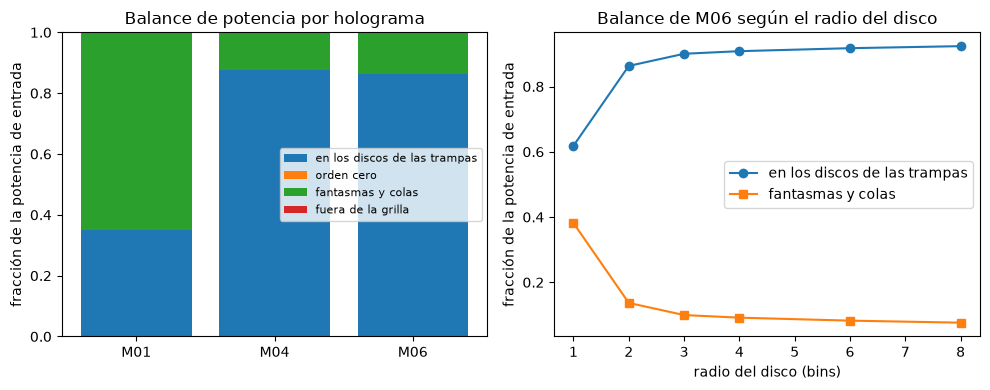

In [10]:
# izquierda: el balance de potencia por holograma; derecha: la parte dentro de los discos frente al radio del disco
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
bottom = np.zeros(len(shares))
labels = {
    "traps": "en los discos de las trampas",
    "zero_order": "orden cero",
    "ghosts": "fantasmas y colas",
    "remainder": "fuera de la grilla",
}
for part, label in labels.items():
    values = np.array([share[part] for share in shares.values()])
    ax1.bar(list(shares), values, bottom=bottom, label=label)
    bottom += values
ax1.set_ylabel("fracción de la potencia de entrada")
ax1.set_title("Balance de potencia por holograma")
ax1.legend(loc="center right", fontsize=8)
ax2.plot(radii, [sweep[r]["traps"] for r in radii], "o-", label="en los discos de las trampas")
ax2.plot(radii, [sweep[r]["ghosts"] for r in radii], "s-", label="fantasmas y colas")
ax2.set_xlabel("radio del disco (bins)")
ax2.set_ylabel("fracción de la potencia de entrada")
ax2.set_title("Balance de M06 según el radio del disco")
ax2.legend()
fig.tight_layout()
plt.show()

Gerchberg-Saxton simple y ponderado ponen 0,8765 y 0,8631 de la potencia de entrada dentro de los discos de las trampas, frente a 0,3517 de la superposición, que envía 0,6483 a fantasmas. Gerchberg-Saxton ponderado compra uniformidad (0,9705 frente a 0,5064) con 0,0134 de la potencia en los discos: es un trato muy bueno, y la eficiencia de picos lo informa como 0,8049 frente a 0,8174. A la derecha, la parte dentro de los discos crece de 0,6184 con un bin a 0,8631 con dos y 0,9237 con ocho, porque un disco más ancho conserva más de la cola de cada punto, y la parte de fantasmas baja de 0,3816 a 0,0763. Un balance debe entonces citarse con su radio. La fracción fuera de la grilla es cero por construcción (la transformada simple conserva la potencia; el valor impreso es redondeo, 2e-16), y el orden cero es menor que 1e-7 en estos tres hologramas (impreso en notación científica arriba), porque ninguno pone luz cerca del eje; solo un modelo de dispositivo llena esas dos barras, como mostró el notebook anterior.

La última figura mira dónde están los fantasmas, dibujando la potencia focal de la superposición y de M06 en escala logarítmica con un círculo en cada bin de trampa.

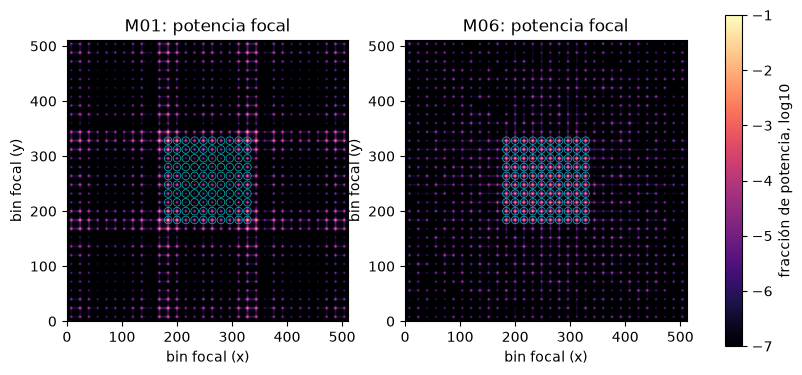

In [11]:
# el plano focal de la superposición y de GS ponderado en escala logarítmica, con los bins de las trampas marcados
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
iy, ix = forward.trap_bins(setup, traps)
for ax, name in zip(axes, ("M01", "M06")):
    power = np.abs(focal[name]) ** 2 * setup.pad**2 / setup.n_pix**2
    image = ax.imshow(np.log10(power + 1e-9), origin="lower", vmin=-7, vmax=-1, cmap="magma")
    ax.scatter(ix, iy, s=30, facecolors="none", edgecolors="c", linewidths=0.5)
    ax.set_title(f"{name}: potencia focal")
    ax.set_xlabel("bin focal (x)")
    ax.set_ylabel("bin focal (y)")
fig.colorbar(image, ax=axes, label="fracción de potencia, log10")
plt.show()

Los fantasmas de la superposición no están dispersos: se ubican en filas y columnas que continúan la red de trampas, que son los órdenes de difracción de un arreglo periódico, y en este holograma llevan casi el doble de potencia que las trampas. Gerchberg-Saxton ponderado tiene la misma red de órdenes débiles, pero llevan 0,1369 de la potencia en vez de 0,6483, y el resto se concentra en los bins marcados. Lo que la figura no puede mostrar es si un fantasma importa: un fantasma que cae sobre una región vacía es inofensivo para una microesfera, y uno que cae sobre el sitio de una trampa es un defecto; el balance por sí solo no distingue los dos casos.

## Resultados

**Respuesta:** Cuatro números leen un arreglo de trampas, y responden cuatro preguntas. En C12 la superposición alcanza una eficiencia de 0,3280 y una uniformidad de 0,0003, con 0,6483 de la potencia en fantasmas; Gerchberg-Saxton simple alcanza 0,8174, 0,5064 y una dispersión de 19,97 por ciento; Gerchberg-Saxton ponderado alcanza 0,8049, 0,9705 y 1,02 por ciento. Las métricas pueden discrepar: con una trampa atenuada al 20 por ciento, un arreglo casi perfecto tiene una uniformidad de 0,3172 y una dispersión de 8,14 por ciento, y queda bajo Gerchberg-Saxton simple por $u$ y sobre él por $\sigma$. Con pesos en el objetivo, la uniformidad cruda de 0,6545 pasa a 0,9813 una vez que las potencias se dividen por los pesos. El balance es función del radio: la parte dentro de los discos es 0,6184 con 1 bin y 0,9237 con 8 bins, de modo que todo balance debe citarse con su radio.

## Resumen

La eficiencia dice cuánta luz llega a las trampas, la uniformidad dice cuán mala es la peor trampa, la dispersión relativa dice cuán parecidas son las trampas típicas y el balance de potencia dice adónde fue el resto de la luz. Ninguna reemplaza a las otras, y la uniformidad es la más dura porque una trampa débil la fija. Un informe justo da al menos la eficiencia, la uniformidad y la dispersión, declara el radio del balance y divide por los pesos cuando el objetivo no es plano. El tema siguiente construye hologramas que no iteran y los mide con estos mismos números.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Polin, Ladavac, Lee, Roichman y Grier, "Optimized holographic optical traps", Optics Express 13, 5831 (2005), https://doi.org/10.1364/OPEX.13.005831.
- Manetsch et al., "A tweezer array with 6100 highly coherent atomic qubits" (2025), https://arxiv.org/abs/2403.12021.